# Takes thresholds: backtest and tuning on 2025

SPEC section 7 lists the Hot Takes detectors and their starting thresholds. This notebook implements each detector in pandas,
replays the 2025 regular season week by week, and checks whether the take **carries information beyond Sleeper's own projection**.
It then picks each detector's main threshold from a small grid and writes `data/takes_thresholds.json`, which the TypeScript
takes engine (`src/takes/**`) reads.

**Backtest design.** For every week `w` from 3 to 17, fire each detector using only data through week `w`. The outcome is
week `w+1`: **actual PPR points minus Sleeper's projection** (soft schedule: the average over the next 3 games).
A "good" take should score above projection, a "bad" take (sell high, red-zone role lost) below it.

In [1]:
import json, time, urllib.request
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 170); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 120)
SEASON = 2025
NFLV = Path('..') / '.cache' / 'nflverse-2025'      # npm run data:nflverse -- --season 2025 --out .cache/nflverse-2025
SLP = Path('..') / '.cache' / 'sleeper-2025'        # Sleeper stats, projections, schedule (cached here)
OUT = Path('..') / 'data' / 'takes_thresholds.json'
SLP.mkdir(parents=True, exist_ok=True)
RNG_SEED = 20251
WEEKS = list(range(3, 18))        # fire weeks w; outcome weeks are w+1 (4..18)
POS = ['QB', 'RB', 'WR', 'TE']

## Data

* **nflverse aggregates** (`weekly`, `teams`, `coverage`) from the repo pipeline, already keyed by Sleeper player id.
* **Sleeper** weekly stats (`pts_ppr` = actual), weekly projections (`stats.pts_ppr` = projection), and the 2025 schedule (opponents).

Sleeper responses are cached under `.cache/sleeper-2025/`, so re-runs are offline.

In [2]:
def fetch(url, path):
    path = Path(path)
    if path.exists() and path.stat().st_size > 100:
        return json.loads(path.read_text())
    for attempt in range(4):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'war-room-notebook'})
            with urllib.request.urlopen(req, timeout=60) as r:
                data = json.load(r)
            path.write_text(json.dumps(data)); time.sleep(0.2)
            return data
        except Exception as e:
            print('retry', url, e); time.sleep(2 * (attempt + 1))
    raise RuntimeError(f'could not fetch {url}')

def columnar(name):
    d = json.load(open(NFLV / name))
    return pd.DataFrame(d['rows'], columns=d['cols'])

weekly = columnar('weekly_2025.json'); teams = columnar('teams_2025.json')
cov_file = json.load(open(NFLV / 'coverage_2025.json')); coverage = pd.DataFrame(cov_file['rows'], columns=cov_file['cols'])
manifest = json.load(open(NFLV / 'manifest.json')); THROUGH = manifest['throughWeek']

stats_rows, proj_rows, info = [], [], {}
PQ = 'season_type=regular&position[]=QB&position[]=RB&position[]=WR&position[]=TE'
for w in range(1, THROUGH + 1):
    st = fetch(f'https://api.sleeper.app/v1/stats/nfl/regular/{SEASON}/{w}', SLP / f'stats_{w}.json')
    for pid, s in st.items():
        if pid[0].isdigit():      # skip team-defense keys like 'TB'
            stats_rows.append((pid, w, s.get('pts_ppr', 0.0) or 0.0, s.get('gp', 0) or 0))
    pj = fetch(f'https://api.sleeper.app/projections/nfl/{SEASON}/{w}?{PQ}', SLP / f'proj_{w}.json')
    for r in pj:
        p = r.get('player') or {}
        info[r['player_id']] = (p.get('position'), ' '.join(filter(None, [p.get('first_name'), p.get('last_name')])))
        proj_rows.append((r['player_id'], w, (r.get('stats') or {}).get('pts_ppr'), r.get('team'), r.get('opponent')))
act = pd.DataFrame(stats_rows, columns=['pid', 'week', 'pts', 'gp'])
proj = pd.DataFrame(proj_rows, columns=['pid', 'week', 'proj', 'team', 'opp'])
proj['proj'] = proj.proj.fillna(0.0)
pinfo = pd.DataFrame([(k, v[0], v[1]) for k, v in info.items()], columns=['pid', 'pos', 'name']).set_index('pid')
sched = pd.DataFrame(fetch(f'https://api.sleeper.app/schedule/nfl/regular/{SEASON}', SLP / 'schedule.json'))
# long schedule: one row per team-week with the opponent (bye weeks have no row)
sched_long = pd.concat([sched[['week', 'home', 'away']].rename(columns={'home': 'team', 'away': 'opp'}),
                        sched[['week', 'home', 'away']].rename(columns={'away': 'team', 'home': 'opp'})]).sort_values(['team', 'week']).reset_index(drop=True)
print(f'nflverse through week {THROUGH}; weekly rows {len(weekly)}, team-weeks {len(teams)}, coverage rows {len(coverage)}')
print(f'Sleeper actuals {len(act)}, projection rows {len(proj)} ({(proj.proj > 3).sum()} above 3 points), schedule games {len(sched)}')

nflverse through week 18; weekly rows 6493, team-weeks 544, coverage rows 524
Sleeper actuals 39929, projection rows 56106 (4181 above 3 points), schedule games 272


## The outcome table

One row per player and fire week `w`, describing week `w+1`.

* **Universe:** players whose week `w+1` projection is above 3 PPR points (the SPEC uses the same cutoff for floors and ceilings). It stands in for "fantasy relevant", and it is known before kickoff. Almost every one of them plays, so no-shows barely matter.
* `resid` = actual minus projection. Sleeper projections run a little high on average, so the notebook also compares every take with the **universe average for the same week and position** (`excess`). That is the fair test of whether the take adds information.
* `hit` = actual beat the projection. `base_hit` = the share of the universe that beat it in the same week and position.

In [3]:
nx = proj.merge(act, on=['pid', 'week'], how='left').merge(pinfo[['pos']], left_on='pid', right_index=True, how='left')
nx['pts'] = nx.pts.fillna(0.0)
nx = nx[(nx.proj > 3) & nx.pos.isin(POS)].copy()
nx['resid'] = nx.pts - nx.proj
nx['hit'] = (nx.resid > 0).astype(float)
nx['base_resid'] = nx.groupby(['week', 'pos']).resid.transform('mean')
nx['base_hit'] = nx.groupby(['week', 'pos']).hit.transform('mean')
nx['excess'] = nx.resid - nx.base_resid
OUT1 = nx.assign(w=nx.week - 1)[['pid', 'w', 'pos', 'team', 'opp', 'proj', 'pts', 'resid', 'hit', 'base_hit', 'excess']]
OUT1 = OUT1[OUT1.w.isin(WEEKS)].reset_index(drop=True)
print(f'universe player-weeks {len(OUT1)} | average actual minus projection {OUT1.resid.mean():+.2f} | MAE {OUT1.resid.abs().mean():.2f} | beat projection {OUT1.hit.mean():.1%}')
print(OUT1.groupby('pos').agg(n=('resid', 'size'), mean_resid=('resid', 'mean'), hit=('hit', 'mean')).round(3))

universe player-weeks 3455 | average actual minus projection -0.71 | MAE 5.24 | beat projection 37.7%
        n  mean_resid    hit
pos                         
QB    449      -2.817  0.350
RB    911      -0.261  0.383
TE    637       0.066  0.405
WR   1458      -0.688  0.370


## Statistics helpers

Bootstrap: 2,000 resamples of **teams** (not rows), so repeated weeks of the same player and teammates in the same offense are not counted as independent evidence. 90% interval from the 5th and 95th percentiles.

In [4]:
def boot_cluster(df, cols, n_boot=2000, seed=RNG_SEED):
    """Cluster bootstrap (by team) of the mean of each column in `cols`. Returns point estimates and 90% CIs."""
    rng = np.random.default_rng(seed)
    g = df.groupby('team')[cols].agg(['sum', 'count'])
    sums = np.stack([g[(c, 'sum')].values for c in cols], 1); cnt = g[(cols[0], 'count')].values.astype(float)
    k = len(cnt); idx = rng.integers(0, k, size=(n_boot, k))
    num = sums[idx].sum(1); den = cnt[idx].sum(1)[:, None]
    m = num / den
    return {c: (df[c].mean(), np.percentile(m[:, i], 5), np.percentile(m[:, i], 95)) for i, c in enumerate(cols)}

N_TEAM_WEEKS = 32 * len(WEEKS)       # team-weeks available for the firing rate

def evaluate(fires, sign=+1, n_boot=2000, team_weeks=N_TEAM_WEEKS):
    """fires: one row per take with pid, w, team, resid, excess, hit, base_hit.
    sign +1 = a good take (should beat the projection), -1 = a bad take (should miss it); a `sgn` column on `fires` overrides it per row.
    Raw columns (mean, excess, hit's complement) are in points over projection; `sx` is the excess in the take's direction (positive = the take was right)."""
    n = len(fires)
    keys = ['n', 'fires_per_team_week', 'mean', 'lo', 'hi', 'excess', 'ex_lo', 'ex_hi', 'sx', 'sx_lo', 'sx_hi', 'hit', 'base_hit', 'hit_lift', 'z']
    if n < 8:
        return dict({k: np.nan for k in keys}, n=n, fires_per_team_week=n / team_weeks)
    s = fires['sgn'].values if 'sgn' in fires else np.full(n, sign)
    f = fires.assign(sx=s * fires.excess, hit_s=np.where(s > 0, fires.hit, 1 - fires.hit), base_s=np.where(s > 0, fires.base_hit, 1 - fires.base_hit))
    f = f.assign(hit_ex=f.hit_s - f.base_s)
    b = boot_cluster(f, ['resid', 'excess', 'sx', 'hit_s', 'hit_ex'], n_boot)
    se = (b['sx'][2] - b['sx'][1]) / 3.29
    return dict(n=n, fires_per_team_week=n / team_weeks, mean=b['resid'][0], lo=b['resid'][1], hi=b['resid'][2],
                excess=b['excess'][0], ex_lo=b['excess'][1], ex_hi=b['excess'][2], sx=b['sx'][0], sx_lo=b['sx'][1], sx_hi=b['sx'][2],
                hit=b['hit_s'][0], base_hit=f.base_s.mean(), hit_lift=b['hit_ex'][0], z=b['sx'][0] / se if se > 0 else np.nan)

## Player-week panel

Weekly nflverse rows joined to the team denominators and to Sleeper points and positions. All rolling features below use only rows through the fire week, in games-played order.

In [5]:
tcols = ['team', 'week', 'pass_att', 'rush_att', 'air_yds', 'i10_pass_att', 'i10_rush_att']
P = weekly.merge(teams[tcols].rename(columns={'air_yds': 'tm_air_yds'}), on=['team', 'week'], how='left')
P = P.merge(pinfo[['pos', 'name']], left_on='pid', right_index=True, how='left').merge(act[['pid', 'week', 'pts']], on=['pid', 'week'], how='left')
P['pts'] = P.pts.fillna(0.0)
P = P[P.pos.isin(POS)].sort_values(['pid', 'week']).reset_index(drop=True)
P['td'] = P.rec_td + P.rush_td
P['xtd'] = P.xtd_rec.fillna(0) + P.xtd_rush.fillna(0)
P['opp_n'] = P.tgt + P.car
P['i10_n'] = P.i10_tgt + P.i10_car
P['tm_i10'] = P.i10_pass_att + P.i10_rush_att
g = P.groupby('pid')
for c in ['tgt', 'pass_att', 'tm_air_yds', 'air_yds', 'td', 'xtd', 'opp_n', 'pts', 'lgt_car', 'lgt_yds', 'bl_tgt', 'bl_yds', 'rec_yds']:
    P['cum_' + c] = g[c].cumsum()
P['games'] = g.cumcount() + 1
print(P.shape, P.pos.value_counts().to_dict())

def attach(df):
    """Join a frame of fires (pid, week) to the next-week outcome; keeps only universe members. `w` is the fire week."""
    d = df.rename(columns={'week': 'w'})
    return d.merge(OUT1, on=['pid', 'w'], how='inner', suffixes=('', '_o'))

(6386, 76) {'WR': 2602, 'TE': 1616, 'RB': 1494, 'QB': 674}


## Detector definitions

Exact definitions, shared with the TypeScript engine. "Rolling k" means the player's last k games in games-played order (through week `w`).
Every player detector requires that he played in week `w`. The `w+1` opponent comes from Sleeper's schedule.

| Detector | Fires at week w when |
|---|---|
| usage_spike | RB/WR/TE snap share in w minus the mean of his previous `baseline_weeks` games is at least `snap_share_jump`, and his team had at least `min_team_snaps` snaps in w |
| target_hog | WR/TE/RB target share over rolling `weeks` (targets / team pass attempts in those games) is at least `min_target_share`, with at least `min_targets` targets |
| buy_low | WR/TE/RB with at least `min_games`: season-to-date air-yards share rank at his position is at most `ay_share_rank_max` and PPR points per game rank is worse than `ppg_rank_min` (rank 1 = best, pool = same position, at least `min_games`) |
| sell_high | RB/WR/TE season-to-date TDs minus xTD is at least `td_over_expected_min`, with at least `min_opportunities` targets plus carries |
| rz_role_change | inside-10 share (targets plus carries over team inside-10 plays) over rolling `weeks`, minus his share in all earlier games, is at least `i10_share_delta` (up) or at most the negative (down); both windows need `min_team_i10_plays` team plays |
| box_count_edge | RB light-box yards per carry at least `ypc_light_min` on at least `min_light_carries`, and his w+1 opponent's season-to-date light-box rate is at least `opp_light_rate_min` |
| blitz_beater | WR/TE yards per target vs blitz minus his overall yards per target is at least `ypt_blitz_over_baseline` on at least `min_blitz_targets` blitz targets, and his w+1 opponent's season-to-date blitz rate is at least `opp_blitz_rate_min` |
| soft_schedule | the defense-vs-position grade (points allowed to the position over the league average, through w) of each of his next `weeks` opponents is at least `dvp_soft_min` |
| waiver_riser, dynasty_mover | not backtestable (see below) |
| coverage_note | in-sample only (see below) |

In [6]:
DEFAULTS = {
    'usage_spike': dict(snap_share_jump=0.15, baseline_weeks=3, min_team_snaps=40),
    'target_hog': dict(min_target_share=0.25, weeks=3, min_targets=15),
    'buy_low': dict(ay_share_rank_max=24, ppg_rank_min=36, min_games=3),
    'sell_high': dict(td_over_expected_min=2, min_opportunities=20),
    'rz_role_change': dict(i10_share_delta=0.2, weeks=3, min_team_i10_plays=6),
    'box_count_edge': dict(ypc_light_min=5.0, opp_light_rate_min=0.35, min_light_carries=15),
    'blitz_beater': dict(ypt_blitz_over_baseline=2.0, opp_blitz_rate_min=0.35, min_blitz_targets=15),
    'soft_schedule': dict(weeks=3, dvp_soft_min=1.15),
    'waiver_riser': dict(min_trending_adds=1000, usage_delta=0.1),
    'dynasty_mover': dict(tail_pct=0.05),
    'coverage_note': dict(yprr_gap_min=0.6, opp_rate_min=0.6, min_routes=20),
}
# cross-checked against the TypeScript contract's current file
cur = json.load(open(OUT))['detectors']
assert all(cur[k].keys() == DEFAULTS[k].keys() for k in DEFAULTS), 'detector keys differ from data/takes_thresholds.json'

def rolling(col, k):
    return g[col].transform(lambda s: s.rolling(k).sum())

def usage_spike(p):
    base = g.snap_pct.transform(lambda s: s.shift(1).rolling(p['baseline_weeks']).mean())
    d = P.assign(jump=P.snap_pct - base)
    d = d[d.pos.isin(['RB', 'WR', 'TE']) & (d.jump >= p['snap_share_jump']) & (d.tm_snaps >= p['min_team_snaps'])]
    return attach(d[['pid', 'week', 'jump']])

def target_hog(p):
    k = p['weeks']
    d = P.assign(tgt_k=rolling('tgt', k), pa_k=rolling('pass_att', k))
    d = d.assign(share_k=d.tgt_k / d.pa_k)
    d = d[d.pos.isin(['RB', 'WR', 'TE']) & (d.share_k >= p['min_target_share']) & (d.tgt_k >= p['min_targets'])]
    return attach(d[['pid', 'week', 'share_k']])

def buy_low(p, positions=('WR', 'TE', 'RB')):
    d = P[P.games >= p['min_games']].copy()
    d['ay_sh'] = d.cum_air_yds / d.cum_tm_air_yds
    d['ppg'] = d.cum_pts / d.games
    # pool at each week: the latest row of every player through that week (players who missed week w still count in the ranks)
    parts = []
    for w in WEEKS:
        pool = d[d.week <= w].sort_values('week').groupby('pid').tail(1)
        pool = pool.assign(ay_rank=pool.groupby('pos').ay_sh.rank(ascending=False, method='min'), ppg_rank=pool.groupby('pos').ppg.rank(ascending=False, method='min'))
        pool = pool[(pool.week == w) & pool.pos.isin(positions)]       # must have played in w
        parts.append(pool.assign(week=w))
    d = pd.concat(parts)
    d = d[(d.ay_rank <= p['ay_share_rank_max']) & (d.ppg_rank > p['ppg_rank_min'])]
    return attach(d[['pid', 'week', 'ay_rank', 'ppg_rank']])

def sell_high(p):
    d = P.assign(gap=P.cum_td - P.cum_xtd)
    d = d[d.pos.isin(['RB', 'WR', 'TE']) & (d.gap >= p['td_over_expected_min']) & (d.cum_opp_n >= p['min_opportunities'])]
    return attach(d[['pid', 'week', 'gap']])

def rz_role_change(p, direction='both'):
    k = p['weeks']
    n_k, t_k = rolling('i10_n', k), rolling('tm_i10', k)
    n_all, t_all = g.i10_n.cumsum(), g.tm_i10.cumsum()
    n_pr, t_pr = n_all - n_k, t_all - t_k
    d = P.assign(recent=n_k / t_k, prior=n_pr / t_pr, t_k=t_k, t_pr=t_pr)
    d['delta'] = d.recent - d.prior
    d = d[d.pos.isin(['RB', 'WR', 'TE']) & (d.t_k >= p['min_team_i10_plays']) & (d.t_pr >= p['min_team_i10_plays'])]
    up, dn = d[d.delta >= p['i10_share_delta']].assign(dir='up'), d[d.delta <= -p['i10_share_delta']].assign(dir='down')
    out = {'both': pd.concat([up, dn]), 'up': up, 'down': dn}[direction]
    return attach(out[['pid', 'week', 'delta', 'dir']])

# team cumulative defense rates through week w, for the w+1 opponent
tw = teams.sort_values(['team', 'week']).copy()
for c in ['def_db', 'def_blitz', 'def_box_car', 'def_light_car']:
    tw['cum_' + c] = tw.groupby('team')[c].cumsum()
tw['cum_blitz_rate'] = tw.cum_def_blitz / tw.cum_def_db
tw['cum_light_rate'] = tw.cum_def_light_car / tw.cum_def_box_car
nxt_opp = sched_long.assign(w=sched_long.week - 1)[['team', 'w', 'opp']].rename(columns={'opp': 'opp_next', 'team': 'team_s'})

def next_opp_rates(d):
    """d has pid, week (fire week), team. Adds the w+1 opponent and its season-to-date blitz / light-box rates through w."""
    d = d.merge(nxt_opp, left_on=['team', 'week'], right_on=['team_s', 'w']).drop(columns=['team_s', 'w'])
    return d.merge(tw[['team', 'week', 'cum_blitz_rate', 'cum_light_rate']], left_on=['opp_next', 'week'], right_on=['team', 'week'], suffixes=('', '_t')).drop(columns='team_t')

def box_count_edge(p):
    d = P.assign(ypc_l=P.cum_lgt_yds / P.cum_lgt_car.replace(0, np.nan))
    d = d[(d.pos == 'RB') & (d.ypc_l >= p['ypc_light_min']) & (d.cum_lgt_car >= p['min_light_carries'])]
    d = next_opp_rates(d)
    d = d[d.cum_light_rate >= p['opp_light_rate_min']]
    return attach(d[['pid', 'week', 'ypc_l', 'cum_light_rate']])

def blitz_beater(p, gate=True):
    d = P.assign(ypt_bl=P.cum_bl_yds / P.cum_bl_tgt.replace(0, np.nan), ypt_all=P.cum_rec_yds / P.cum_tgt.replace(0, np.nan))
    d = d.assign(edge=d.ypt_bl - d.ypt_all)
    d = d[d.pos.isin(['WR', 'TE']) & (d.edge >= p['ypt_blitz_over_baseline']) & (d.cum_bl_tgt >= p['min_blitz_targets'])]
    d = next_opp_rates(d)
    if gate:
        d = d[d.cum_blitz_rate >= p['opp_blitz_rate_min']]
    return attach(d[['pid', 'week', 'edge', 'cum_blitz_rate']])

### Soft schedule

Defense-vs-position grade: for each defense, the average PPR points the players of a position scored against it in games through `w`, divided by the league mean of those averages. Soft is 1.15 or higher (SPEC section 5). The outcome averages `actual - projection` over the next 3 games (each game needs a projection above 3, and the take needs at least 2 such games).

In [7]:
dv = P.merge(sched_long.rename(columns={'opp': 'opp_s', 'team': 'team_s'}), left_on=['team', 'week'], right_on=['team_s', 'week'], how='left')
dv = dv.groupby(['opp_s', 'pos', 'week']).pts.sum().rename('allowed').reset_index().rename(columns={'opp_s': 'defense'})
dvp = {}
allw = sorted(sched_long.week.unique())
for pos in POS:
    t = dv[dv.pos == pos].pivot(index='week', columns='defense', values='allowed').reindex(allw)
    played = sched_long.pivot(index='week', columns='team', values='opp').reindex(allw).notna()      # defense played that week
    cum = t.fillna(0).cumsum() ; gms = played.cumsum().replace(0, np.nan)
    avg = cum / gms.reindex(columns=cum.columns)
    dvp[pos] = avg.div(avg.mean(axis=1), axis=0)            # ratio to the league mean, row = through week
dvp_long = pd.concat({pos: df.stack().rename('dvp') for pos, df in dvp.items()}, names=['pos', 'thru', 'defense']).reset_index()

# next 3 scheduled games per team after w
sl = sched_long.copy()
fut = []
for w in WEEKS:
    f = sl[sl.week > w].groupby('team').head(3).assign(w=w)
    f['k'] = f.groupby('team').cumcount()
    fut.append(f)
fut = pd.concat(fut)

def soft_schedule(p):
    k = p['weeks']
    u = OUT1[['pid', 'w', 'pos', 'team']].copy()          # one row per universe player-week (team = w+1 team)
    f = u.merge(fut[fut.k < k], on=['team', 'w'])
    f = f.merge(dvp_long, left_on=['pos', 'w', 'opp'], right_on=['pos', 'thru', 'defense'], how='left')
    full = f.groupby(['pid', 'w']).agg(n=('dvp', 'size'), lo=('dvp', 'min')).reset_index()
    full = full[(full.n == k) & (full.lo >= p['dvp_soft_min'])]
    # outcome: mean actual - projection over those k games (>=2 with a projection above 3)
    games = full.merge(f[['pid', 'w', 'week', 'team']], on=['pid', 'w'])
    games = games.merge(nx_all, on=['pid', 'week'], how='inner')
    o = games.groupby(['pid', 'w']).agg(n_g=('resid', 'size'), resid=('resid', 'mean'), excess=('excess', 'mean'), hit_mean=('resid', lambda s: s.mean() > 0),
                                        base_hit=('base_hit', 'mean'), team=('team', 'first')).reset_index()
    o = o[o.n_g >= 2]
    o['hit'] = o.hit_mean.astype(float)
    return o

# outcome rows for any week (soft schedule looks 1 to 3 weeks ahead): the same universe as OUT1 but keyed by the game week
nx_all = nx[['pid', 'week', 'resid', 'excess', 'base_hit']]
print('detectors defined')

detectors defined


## Detectors that cannot be backtested

* **waiver_riser** needs Sleeper's trending-adds history. The trending endpoint is a rolling snapshot (last 24 hours) with no history, and nothing was captured during 2025.
* **dynasty_mover** needs FantasyCalc's 30-day value change, and FantasyCalc keeps no value history either.

Both keep their SPEC defaults, with no evidence attached.

* **coverage_note** needs participation data, which exists for 2025 only. The man/zone splits are season totals, so a 2025 backtest uses a split that already contains the outcome week: **in-sample only, optimistic by construction**. It is reported as a sanity check and its defaults are kept.

## Backtest at the SPEC defaults

One row per detector. `mean` is actual minus projection in the following week. `excess` removes the universe average for the same week and position. `hit` is the share of takes that went the way the take says (above projection for good takes, below for sell high), `base` the same share for the whole universe.

In [8]:
D = DEFAULTS
TEAM_WEEKS = {'soft_schedule': 32 * len([w for w in WEEKS if w <= 15])}      # needs 3 more games, so fire weeks 3-15 only
SIGN = {'usage_spike': +1, 'target_hog': +1, 'buy_low': +1, 'sell_high': -1, 'rz_role_change': 0, 'box_count_edge': +1, 'blitz_beater': +1, 'soft_schedule': +1}

def rz_fires(p):
    f = rz_role_change(p)
    return f.assign(sgn=np.where(f['dir'] == 'up', +1, -1))

FIRE = {
    'usage_spike': usage_spike, 'target_hog': target_hog, 'buy_low': buy_low, 'sell_high': sell_high, 'rz_role_change': rz_fires,
    'box_count_edge': box_count_edge, 'blitz_beater': blitz_beater, 'soft_schedule': soft_schedule,
}
def run(name, p, n_boot=2000):
    f = FIRE[name](p)
    return evaluate(f, SIGN[name] or +1, n_boot, TEAM_WEEKS.get(name, N_TEAM_WEEKS)), f

base_rows = []
for name in FIRE:
    r, _ = run(name, D[name]); base_rows.append(dict(detector=name, **r))
base = pd.DataFrame(base_rows).set_index('detector')
base[['n', 'fires_per_team_week', 'mean', 'lo', 'hi', 'excess', 'ex_lo', 'ex_hi', 'hit', 'base_hit']].round(3)

,n,fires_per_team_week,mean,lo,hi,excess,ex_lo,ex_hi,hit,base_hit
detector,,,,,,,,,,
usage_spike,373,0.777,-0.548,-1.112,0.005,-0.131,-0.691,0.425,0.357,0.382
target_hog,207,0.431,-0.659,-1.715,0.350,-0.018,-1.033,0.943,0.386,0.371
buy_low,127,0.265,0.609,-0.598,2.059,0.883,-0.310,2.356,0.433,0.385
sell_high,182,0.379,-1.429,-2.412,-0.515,-0.872,-1.850,0.053,0.659,0.627
rz_role_change,191,0.398,-0.151,-1.073,0.821,0.208,-0.682,1.169,0.476,0.482
box_count_edge,174,0.362,-0.779,-1.616,0.005,-0.501,-1.339,0.282,0.356,0.387
blitz_beater,19,0.040,-2.466,-4.695,0.041,-1.409,-3.592,1.091,0.263,0.352
soft_schedule,24,0.058,0.041,-1.161,1.980,0.068,-0.860,1.490,0.542,0.419


## Tuning

For each detector, a small grid on its main threshold, all other parameters at their defaults (buy low has two thresholds that define it, so it gets a small 2-D grid).

**Selection rule** (fixed before looking at results, designed not to chase noise):

1. A grid value is a *candidate* if it fires at most **0.40 times per team per week** and has at least **40 takes**.
2. A candidate shows a *clear signal* if the 90% CI of its excess (in the take's direction) sits above **0.25 points** (a practical margin, not just above zero) and its hit rate beats the universe's.
3. Keep the default if it has a clear signal. Otherwise move to the clear-signal candidate closest to the default on the grid.
4. If no candidate has a clear signal: keep the default when its volume is within the cap, else take the candidate closest to the default. That is a volume-only change, not a claim about signal.

Tuning and testing use the same season, so any chosen value's numbers are optimistic. The split-half check below repeats the chosen setting on weeks 3-10 and 11-17.

In [9]:
GRIDS = {
    'usage_spike': ('snap_share_jump', [0.10, 0.15, 0.20, 0.25, 0.30, 0.35]),
    'target_hog': ('min_target_share', [0.20, 0.225, 0.25, 0.275, 0.30, 0.325]),
    'sell_high': ('td_over_expected_min', [1.0, 1.5, 2.0, 2.5, 3.0, 3.5]),
    'rz_role_change': ('i10_share_delta', [0.10, 0.15, 0.20, 0.25, 0.30, 0.40]),
    'box_count_edge': ('ypc_light_min', [4.5, 5.0, 5.5, 6.0, 6.5]),
    'blitz_beater': ('ypt_blitz_over_baseline', [1.0, 1.5, 2.0, 2.5, 3.0]),
    'soft_schedule': ('dvp_soft_min', [1.00, 1.05, 1.10, 1.15, 1.20, 1.25]),
}
BUY_AY, BUY_PPG = [12, 18, 24, 30, 36], [24, 30, 36, 42]
CAP, MIN_N, MARGIN = 0.40, 40, 0.25

def sweep(name, key, grid):
    rows = []
    for v in grid:
        p = dict(D[name]); p[key] = v
        r, _ = run(name, p, 1000); rows.append(dict(value=v, **r))
    return pd.DataFrame(rows).set_index('value')

def choose(tab, default, dist):
    """tab: sweep table indexed by grid value. dist(value) = grid distance to the default. Returns (value, reason)."""
    cand = tab[(tab.fires_per_team_week <= CAP) & (tab.n >= MIN_N)]
    clear = cand[(cand.sx_lo > MARGIN) & (cand.hit_lift > 0)]
    d_row = tab.loc[default]
    if default in clear.index: return default, 'default shows a clear signal'
    if len(clear):
        v = sorted(clear.index, key=lambda x: (dist(x), -clear.loc[x, 'z']))[0]
        return v, 'closest value with a clear signal'
    if d_row.fires_per_team_week <= CAP: return default, 'no value shows a clear signal; default volume is within the cap'
    if len(cand): return sorted(cand.index, key=dist)[0], 'no clear signal anywhere; tightened only to fit the volume cap'
    return default, 'no candidate; default kept'

sweeps, chosen, why = {}, {}, {}
for name, (key, grid) in GRIDS.items():
    tab = sweep(name, key, grid); sweeps[name] = tab
    idx = {v: i for i, v in enumerate(grid)}
    chosen[name], why[name] = choose(tab, D[name][key], lambda x, d=D[name][key], idx=idx: abs(idx[x] - idx[d]))
    print(f'{name:15s} {key:25s} default {D[name][key]} -> {chosen[name]}   ({why[name]})')

usage_spike     snap_share_jump           default 0.15 -> 0.25   (no clear signal anywhere; tightened only to fit the volume cap)


target_hog      min_target_share          default 0.25 -> 0.275   (no clear signal anywhere; tightened only to fit the volume cap)
sell_high       td_over_expected_min      default 2 -> 2.5   (closest value with a clear signal)


rz_role_change  i10_share_delta           default 0.2 -> 0.2   (no value shows a clear signal; default volume is within the cap)
box_count_edge  ypc_light_min             default 5.0 -> 5.0   (no value shows a clear signal; default volume is within the cap)
blitz_beater    ypt_blitz_over_baseline   default 2.0 -> 2.0   (no value shows a clear signal; default volume is within the cap)
soft_schedule   dvp_soft_min              default 1.15 -> 1.15   (no value shows a clear signal; default volume is within the cap)


Grid results (excess is in points over the universe average; `sx` is that excess in the take's direction, so positive means the take was right; rz_role_change pools up and down takes).

In [10]:
show = ['n', 'fires_per_team_week', 'mean', 'excess', 'sx', 'sx_lo', 'sx_hi', 'hit', 'base_hit', 'hit_lift']
for name, tab in sweeps.items():
    print(f'--- {name}: {GRIDS[name][0]} (default {D[name][GRIDS[name][0]]}, chosen {chosen[name]})')
    print(tab[show].round(3).to_string())

--- usage_spike: snap_share_jump (default 0.15, chosen 0.25)
         n  fires_per_team_week   mean  excess     sx  sx_lo  sx_hi    hit  base_hit  hit_lift
value                                                                                         
0.10   604                1.258 -0.781  -0.360 -0.360 -0.852  0.128  0.359     0.381    -0.022
0.15   373                0.777 -0.548  -0.131 -0.131 -0.697  0.423  0.357     0.382    -0.026
0.20   229                0.477 -0.356   0.102  0.102 -0.587  0.801  0.341     0.380    -0.040
0.25   162                0.338 -0.119   0.362  0.362 -0.509  1.276  0.352     0.377    -0.026
0.30   113                0.235  0.385   0.905  0.905 -0.232  2.049  0.363     0.375    -0.012
0.35    74                0.154  0.243   0.849  0.849 -0.218  1.876  0.365     0.373    -0.008
--- target_hog: min_target_share (default 0.25, chosen 0.275)
         n  fires_per_team_week   mean  excess     sx  sx_lo  sx_hi    hit  base_hit  hit_lift
value                 

### Buy low: two thresholds

In [11]:
rows = []
for ay in BUY_AY:
    for pp in BUY_PPG:
        p = dict(D['buy_low'], ay_share_rank_max=ay, ppg_rank_min=pp)
        r, _ = run('buy_low', p, 1000); rows.append(dict(ay_share_rank_max=ay, ppg_rank_min=pp, **r))
bl2 = pd.DataFrame(rows).set_index(['ay_share_rank_max', 'ppg_rank_min'])
print(bl2[show].round(3).to_string())
cand = bl2[(bl2.fires_per_team_week <= CAP) & (bl2.n >= MIN_N)]
clear = cand[(cand.sx_lo > MARGIN) & (cand.hit_lift > 0)]
dflt = (24, 36)
gi = lambda t: (BUY_AY.index(t[0]), BUY_PPG.index(t[1]))
dist2 = lambda t: abs(gi(t)[0] - gi(dflt)[0]) + abs(gi(t)[1] - gi(dflt)[1])
if dflt in clear.index: bl_choice, bl_why = dflt, 'default shows a clear signal'
elif len(clear): bl_choice, bl_why = sorted(clear.index, key=lambda t: (dist2(t), -clear.loc[t, 'z']))[0], 'closest value with a clear signal'
elif bl2.loc[dflt].fires_per_team_week <= CAP: bl_choice, bl_why = dflt, 'no value shows a clear signal; default volume is within the cap'
else: bl_choice, bl_why = sorted(cand.index, key=dist2)[0], 'tightened only to fit the volume cap'
chosen['buy_low'], why['buy_low'] = bl_choice, bl_why
sweeps['buy_low'] = bl2
print('buy_low', dflt, '->', bl_choice, f'({bl_why})')

                                  n  fires_per_team_week   mean  excess     sx  sx_lo  sx_hi    hit  base_hit  hit_lift
ay_share_rank_max ppg_rank_min                                                                                         
12                24            101                0.210  0.294   0.634  0.634 -0.808  2.221  0.426     0.383     0.043
                  30             80                0.167  0.527   0.919  0.919 -0.641  2.569  0.450     0.379     0.071
                  36             50                0.104  2.211   2.480  2.480  0.203  5.353  0.560     0.388     0.172
                  42             35                0.073  1.750   1.968  1.968  0.081  5.632  0.514     0.389     0.125
18                24            158                0.329  0.227   0.543  0.543 -0.506  1.665  0.405     0.381     0.024
                  30            122                0.254  0.405   0.744  0.744 -0.396  1.959  0.426     0.380     0.046
                  36             82     

### The secondary gates (not tuned, shown for context)

Box-count edge and blitz beater pair a player stat with an opponent tendency. If the opponent gate does nothing, the pairing is cosmetic. Left unchanged unless noted, but worth knowing.

In [12]:
gate = []
for v in [0.35, 0.50, 0.60, 0.70]:
    r, _ = run('box_count_edge', dict(D['box_count_edge'], opp_light_rate_min=v), 1000); gate.append(dict(detector='box_count_edge', gate='opp_light_rate_min', value=v, **r))
for v in [0.0, 0.25, 0.30, 0.35]:
    r, _ = run('blitz_beater', dict(D['blitz_beater'], opp_blitz_rate_min=v), 1000); gate.append(dict(detector='blitz_beater', gate='opp_blitz_rate_min', value=v, **r))
gate = pd.DataFrame(gate).set_index(['detector', 'gate', 'value'])
print(gate[['n', 'fires_per_team_week', 'excess', 'ex_lo', 'ex_hi', 'hit_lift']].round(3).to_string())
lr = teams.def_light_rate.dropna(); br = teams.def_blitz_rate.dropna()
print(f'\nLeague light-box rate across team-weeks: mean {lr.mean():.2f}, 25th percentile {lr.quantile(.25):.2f}. Blitz rate: mean {br.mean():.2f}, 75th percentile {br.quantile(.75):.2f}.')
print(f'Share of team-weeks at or above the default light-box gate (0.35): {(lr >= 0.35).mean():.0%}. At or above the default blitz gate (0.35): {(br >= 0.35).mean():.0%}.')

                                           n  fires_per_team_week  excess  ex_lo  ex_hi  hit_lift
detector       gate               value                                                          
box_count_edge opp_light_rate_min 0.35   174                0.362  -0.501 -1.341  0.294    -0.031
                                  0.50   137                0.285  -0.149 -0.960  0.664     0.007
                                  0.60    91                0.190  -0.320 -1.568  0.895     0.000
                                  0.70    38                0.079   0.220 -1.716  2.390     0.059
blitz_beater   opp_blitz_rate_min 0.00    95                0.198   0.491 -0.728  1.716     0.034
                                  0.25    75                0.156   0.643 -0.834  2.175     0.028
                                  0.30    40                0.083   0.076 -1.622  1.783    -0.026
                                  0.35    19                0.040  -1.409 -3.552  1.116    -0.089

League light-box ra

## Coverage note (in-sample only)

For each universe player-week in weeks 4-18: the player's yards-per-route gap between man and zone (full-season split, so it includes the outcome week) is matched against the opponent's season man rate. Needs `min_routes` routes in both splits. A man-beater matches a defense that is at least `opp_rate_min` man; a zone-beater matches a defense that is at least `opp_rate_min` zone. Reported to see whether the idea is dead on arrival, **not** as evidence for a threshold.

In [13]:
tm = pd.DataFrame(cov_file['teams']).T.assign(man_rate=lambda d: d.man_rate.astype(float))
cvr = coverage.assign(gap=coverage.yprr_man - coverage.yprr_zone)
def coverage_note(p):
    c = cvr[(cvr.man_routes >= p['min_routes']) & (cvr.zone_routes >= p['min_routes'])]
    d = nx.merge(c[['pid', 'gap']], on='pid').merge(tm[['man_rate']], left_on='opp', right_index=True)
    man_match = (d.gap >= p['yprr_gap_min']) & (d.man_rate >= p['opp_rate_min'])
    zone_match = (d.gap <= -p['yprr_gap_min']) & ((1 - d.man_rate) >= p['opp_rate_min'])
    d = d[man_match | zone_match].assign(w=lambda x: x.week - 1, side=np.where(man_match, 'man', 'zone')[(man_match | zone_match).values])
    return d[['pid', 'w', 'team', 'resid', 'excess', 'hit', 'base_hit', 'side']]
rows = []
for gmin in [0.3, 0.45, 0.6, 0.8, 1.0]:
    for rmin in [0.4, 0.5, 0.6, 0.7]:
        f = coverage_note(dict(D['coverage_note'], yprr_gap_min=gmin, opp_rate_min=rmin))
        r = evaluate(f, +1, 500); rows.append(dict(yprr_gap_min=gmin, opp_rate_min=rmin, man_side=int((f.side == 'man').sum()), **r))
cov_grid = pd.DataFrame(rows).set_index(['yprr_gap_min', 'opp_rate_min'])
print(cov_grid[['n', 'man_side', 'fires_per_team_week', 'mean', 'excess', 'ex_lo', 'ex_hi', 'hit', 'base_hit']].round(3).to_string())
print(f'defenses with man rate >= 0.6: {(tm.man_rate >= 0.6).sum()}; >= 0.5: {(tm.man_rate >= 0.5).sum()}; max {tm.man_rate.max():.2f}')
cov_default, cov_f = evaluate(coverage_note(D['coverage_note']), +1), coverage_note(D['coverage_note'])

                              n  man_side  fires_per_team_week   mean  excess  ex_lo  ex_hi    hit  base_hit
yprr_gap_min opp_rate_min                                                                                   
0.30         0.4           1679       171                3.498 -0.335   0.094 -0.192  0.353  0.398     0.383
             0.5           1508         0                3.142 -0.348   0.064 -0.205  0.343  0.400     0.383
             0.6           1267         0                2.640 -0.320   0.092 -0.247  0.387  0.400     0.383
             0.7            715         0                1.490 -0.146   0.271 -0.227  0.777  0.421     0.383
0.45         0.4           1185       127                2.469 -0.217   0.208 -0.065  0.470  0.404     0.383
             0.5           1058         0                2.204 -0.232   0.172 -0.095  0.457  0.405     0.384
             0.6            888         0                1.850 -0.146   0.263 -0.092  0.607  0.409     0.383
             0.7   

## Final thresholds and their evidence

Re-run every detector at the chosen threshold, with 5,000 bootstrap draws for the reported intervals.

In [14]:
FINAL = {k: dict(v) for k, v in DEFAULTS.items()}
for name, (key, _) in GRIDS.items():
    FINAL[name][key] = chosen[name]
FINAL['buy_low'].update(ay_share_rank_max=chosen['buy_low'][0], ppg_rank_min=chosen['buy_low'][1])

MAIN = {'usage_spike': ['snap_share_jump'], 'target_hog': ['min_target_share'], 'buy_low': ['ay_share_rank_max', 'ppg_rank_min'], 'sell_high': ['td_over_expected_min'],
        'rz_role_change': ['i10_share_delta'], 'box_count_edge': ['ypc_light_min'], 'blitz_beater': ['ypt_blitz_over_baseline'], 'soft_schedule': ['dvp_soft_min']}
final, fires_final = {}, {}
for name in FIRE:
    r, f = run(name, FINAL[name], 5000); final[name] = r; fires_final[name] = f
    rd, fd = run(name, DEFAULTS[name], 5000); final[name]['default_stats'] = rd

def verdict(r):
    if not np.isfinite(r['sx']): return 'too_few'
    if r['sx_lo'] > 0 and r['hit_lift'] > 0: return 'signal'
    if r['sx_hi'] < 0: return 'wrong_way'
    if r['sx'] > 0 and r['hit_lift'] > 0: return 'weak'
    return 'leans_wrong' if r['sx'] < 0 and r['hit_lift'] < 0 else 'none'
for name, r in final.items(): r['verdict'] = verdict(r)

# direction detail for red-zone role change
rz_split = {d: evaluate(fires_final['rz_role_change'].query('dir == @d'), +1 if d == 'up' else -1, 5000) for d in ['up', 'down']}

def fmt_thr(name, which):
    vals = {k: (FINAL if which == 'chosen' else DEFAULTS)[name][k] for k in MAIN[name]}
    return ', '.join(f'{k}={v}' for k, v in vals.items())

tbl = []
for name, r in final.items():
    if name == 'rz_role_change':
        for d, rr in rz_split.items():
            tbl.append(dict(detector=f'rz_role_change ({d})', default=fmt_thr(name, 'default'), chosen=fmt_thr(name, 'chosen'), n=rr['n'], mean=rr['mean'], lo=rr['lo'], hi=rr['hi'],
                            excess=rr['excess'], hit=rr['hit'], base=rr['base_hit'], fires=rr['fires_per_team_week'], verdict=verdict(rr)))
    else:
        tbl.append(dict(detector=name, default=fmt_thr(name, 'default'), chosen=fmt_thr(name, 'chosen'), n=r['n'], mean=r['mean'], lo=r['lo'], hi=r['hi'],
                        excess=r['excess'], hit=r['hit'], base=r['base_hit'], fires=r['fires_per_team_week'], verdict=r['verdict']))
summary = pd.DataFrame(tbl).set_index('detector')
disp = summary.copy()
disp['mean over proj'] = [f'{m:+.2f} [{l:+.2f}, {h:+.2f}]' for m, l, h in zip(summary['mean'], summary.lo, summary.hi)]
disp['excess vs universe'] = [f'{e:+.2f}' for e in summary.excess]
disp['hit in direction (universe)'] = [f'{h:.0%} ({b:.0%})' for h, b in zip(summary.hit, summary.base)]
disp['fires/team-wk'] = [f'{f:.2f}' for f in summary.fires]
disp['n'] = summary.n.astype(int)
disp[['default', 'chosen', 'n', 'mean over proj', 'excess vs universe', 'hit in direction (universe)', 'fires/team-wk', 'verdict']]

,default,chosen,n,mean over proj,excess vs universe,hit in direction (universe),fires/team-wk,verdict
detector,,,,,,,,
usage_spike,snap_share_jump=0.15,snap_share_jump=0.25,162,"-0.12 [-1.00, +0.75]",+0.36,35% (38%),0.34,none
target_hog,min_target_share=0.25,min_target_share=0.275,119,"-0.06 [-1.34, +1.30]",+0.63,45% (37%),0.25,weak
buy_low,"ay_share_rank_max=24, ppg_rank_min=36","ay_share_rank_max=24, ppg_rank_min=36",127,"+0.61 [-0.60, +2.04]",+0.88,43% (38%),0.26,weak
sell_high,td_over_expected_min=2,td_over_expected_min=2.5,112,"-2.15 [-3.45, -1.02]",-1.52,69% (63%),0.23,signal
rz_role_change (up),i10_share_delta=0.2,i10_share_delta=0.2,109,"-0.45 [-1.64, +0.85]",-0.02,39% (39%),0.23,none
rz_role_change (down),i10_share_delta=0.2,i10_share_delta=0.2,82,"+0.25 [-1.07, +1.71]",+0.51,59% (61%),0.17,leans_wrong
box_count_edge,ypc_light_min=5.0,ypc_light_min=5.0,174,"-0.78 [-1.59, -0.03]",-0.50,36% (39%),0.36,leans_wrong
blitz_beater,ypt_blitz_over_baseline=2.0,ypt_blitz_over_baseline=2.0,19,"-2.47 [-4.69, -0.06]",-1.41,26% (35%),0.04,leans_wrong
soft_schedule,dvp_soft_min=1.15,dvp_soft_min=1.15,24,"+0.04 [-1.17, +1.98]",+0.07,54% (42%),0.06,weak


### Chart: excess over projection, in the take's direction

Each bar is the average points a take beat (or, for sell high, missed) its projection by relative to the same week and position, with the 90% interval. Right of zero means the take was right.

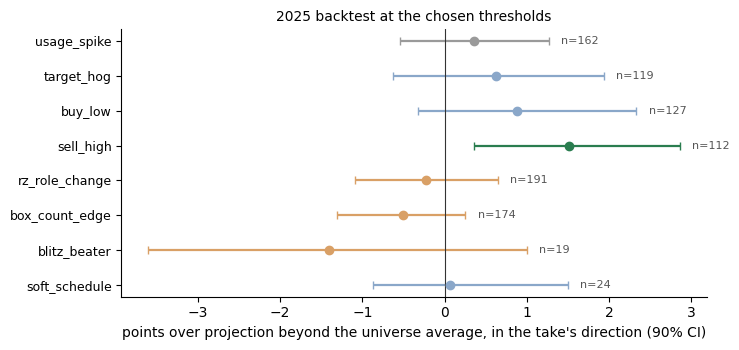

In [15]:
order = ['usage_spike', 'target_hog', 'buy_low', 'sell_high', 'rz_role_change', 'box_count_edge', 'blitz_beater', 'soft_schedule']
colors = {'signal': '#2a7d4f', 'weak': '#8aa7c9', 'none': '#9a9a9a', 'leans_wrong': '#d9a066', 'wrong_way': '#b5483a', 'too_few': '#cccccc'}
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for i, name in enumerate(order[::-1]):
    r = final[name]
    ax.errorbar(r['sx'], i, xerr=[[r['sx'] - r['sx_lo']], [r['sx_hi'] - r['sx']]], fmt='o', color=colors[r['verdict']], capsize=3, lw=1.6)
    ax.text(max(r['sx_hi'], 0) + 0.15, i, f"n={r['n']}", va='center', fontsize=8, color='#555')
ax.axvline(0, color='#333', lw=0.8)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order[::-1], fontsize=9)
ax.set_xlabel('points over projection beyond the universe average, in the take\'s direction (90% CI)')
ax.set_title('2025 backtest at the chosen thresholds', fontsize=10)
for s in ['top', 'right']: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## Checks: split-half and feed volume

**Split-half:** the chosen setting on fire weeks 3-10 vs 11-17 (excess in the take's direction; the point estimate only, the halves are small).

**Feed volume:** all backtestable detectors together at the chosen thresholds, takes per NFL team per week among fantasy-relevant players (week w+1 projection above 3). Coverage note is added in-sample. Waiver riser and dynasty mover are not simulated; they fire for few players.

In [16]:
halves = []
for name in order:
    f = fires_final[name]
    sgn = f['sgn'] if 'sgn' in f else pd.Series(SIGN[name], index=f.index)
    for lab, m in [('weeks 3-10', f.w <= 10), ('weeks 11-17', f.w >= 11)]:
        sub = f[m]; s = sgn[m]
        halves.append(dict(detector=name, half=lab, n=len(sub), signed_excess=float((s * sub.excess).mean()) if len(sub) else np.nan))
halves = pd.DataFrame(halves).pivot(index='detector', columns='half', values=['n', 'signed_excess']).reindex(order)
print(halves.round(2).to_string())

parts = [f.assign(kind=k)[['pid', 'w', 'team', 'kind']] for k, f in fires_final.items()]
parts.append(coverage_note(FINAL['coverage_note']).assign(kind='coverage_note')[['pid', 'w', 'team', 'kind']])
allf = pd.concat(parts, ignore_index=True)
grid_tw = pd.MultiIndex.from_product([sorted(OUT1.team.dropna().unique()), WEEKS], names=['team', 'w'])
per_tw = allf.groupby(['team', 'w']).size().reindex(grid_tw, fill_value=0)
per_pw = allf.groupby(['pid', 'w']).size()
per_tw_x = allf[allf.kind != 'coverage_note'].groupby(['team', 'w']).size().reindex(grid_tw, fill_value=0)
volume = dict(mean_per_team_week=float(per_tw.mean()), mean_excl_coverage_note=float(per_tw_x.mean()), p90_excl_coverage_note=float(per_tw_x.quantile(0.9)), median=float(per_tw.median()), p90=float(per_tw.quantile(0.9)), max=int(per_tw.max()),
              share_team_weeks_empty=float((per_tw == 0).mean()), takes_total=int(len(allf)),
              player_weeks_over_3=int((per_pw > 3).sum()), max_takes_one_player_week=int(per_pw.max()))
by_kind = allf.groupby('kind').size().div(len(grid_tw)).round(3)
print('\nfeed volume at the chosen thresholds:', {k: round(v, 3) for k, v in volume.items()})
print((allf.groupby('kind').size() / len(grid_tw)).round(3).to_string())
dflt_parts = [run(k, DEFAULTS[k], 500)[1].assign(kind=k)[['pid', 'w', 'team', 'kind']] for k in FIRE]
dflt_parts.append(coverage_note(DEFAULTS['coverage_note']).assign(kind='coverage_note')[['pid', 'w', 'team', 'kind']])
print(f'for comparison, at the SPEC defaults: {sum(len(x) for x in dflt_parts) / len(grid_tw):.2f} takes per team-week')

                         n            signed_excess           
half           weeks 11-17 weeks 3-10   weeks 11-17 weeks 3-10
detector                                                      
usage_spike           98.0       64.0          0.50       0.14
target_hog            57.0       62.0          0.98       0.30
buy_low               54.0       73.0          0.86       0.90
sell_high             75.0       37.0          0.88       2.81
rz_role_change       103.0       88.0         -0.64       0.26
box_count_edge        94.0       80.0         -0.29      -0.75
blitz_beater          14.0        5.0         -0.83      -3.04
soft_schedule         14.0       10.0         -0.40       0.73

feed volume at the chosen thresholds: {'mean_per_team_week': 2.871, 'mean_excl_coverage_note': 1.933, 'p90_excl_coverage_note': 4.0, 'median': 3.0, 'p90': 5.0, 'max': 10, 'share_team_weeks_empty': 0.125, 'takes_total': 1470, 'player_weeks_over_3': 1, 'max_takes_one_player_week': 4}
kind
blitz_beater      

for comparison, at the SPEC defaults: 3.83 takes per team-week


## Write `data/takes_thresholds.json`

Same keys and shape as `TakesThresholds` in `src/takes/types.ts`. Everything in `evidence` is free-form: per detector, the numbers behind the choice and a suggested tone (a clear signal keeps the SPEC tone; a weak but positive result keeps it only if it is positive in both halves; everything else is better shown as `watch`).

In [17]:
def clean(x):
    if isinstance(x, dict): return {k: clean(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)): return [clean(v) for v in x]
    if isinstance(x, (np.integer,)): return int(x)
    if isinstance(x, (np.floating, float)): return None if not np.isfinite(x) else round(float(x), 3)
    return x

SPEC_TONE = {'usage_spike': 'good', 'target_hog': 'good', 'buy_low': 'good', 'sell_high': 'bad', 'rz_role_change': 'watch', 'box_count_edge': 'good', 'blitz_beater': 'good', 'soft_schedule': 'good'}
def replicates(name):
    return bool(halves.loc[name, ('signed_excess', 'weeks 3-10')] > 0 and halves.loc[name, ('signed_excess', 'weeks 11-17')] > 0)

def ev(name, r):
    d = DEFAULTS[name]; c = FINAL[name]
    out = dict(
        backtested=True, main_threshold={k: dict(default=d[k], chosen=c[k]) for k in MAIN[name]}, why_chosen=why[name],
        n=r['n'], mean_over_projection=r['mean'], ci90=[r['lo'], r['hi']],
        excess_vs_universe=r['excess'], excess_ci90=[r['ex_lo'], r['ex_hi']],
        excess_in_take_direction=r['sx'], hit_rate=r['hit'], universe_hit_rate=r['base_hit'], fires_per_team_week=r['fires_per_team_week'],
        verdict=r['verdict'], positive_in_both_halves=replicates(name),
        suggested_tone=SPEC_TONE[name] if (r['verdict'] == 'signal' or (r['verdict'] == 'weak' and replicates(name))) else 'watch',
        at_default=dict(n=r['default_stats']['n'], mean_over_projection=r['default_stats']['mean'], ci90=[r['default_stats']['lo'], r['default_stats']['hi']],
                        excess_vs_universe=r['default_stats']['excess'], hit_rate=r['default_stats']['hit'], fires_per_team_week=r['default_stats']['fires_per_team_week']),
    )
    return out
evidence = {k: ev(k, v) for k, v in final.items()}
evidence['rz_role_change']['by_direction'] = {d: dict(n=r['n'], mean_over_projection=r['mean'], ci90=[r['lo'], r['hi']], excess_vs_universe=r['excess'], hit_rate=r['hit'], fires_per_team_week=r['fires_per_team_week']) for d, r in rz_split.items()}
for blk in (evidence['rz_role_change'], evidence['rz_role_change']['at_default']):
    for k in ['mean_over_projection', 'ci90', 'excess_vs_universe', 'excess_ci90']:
        if k in blk: blk[k] = None
evidence['rz_role_change']['note'] = 'up and down takes are pooled: only excess_in_take_direction, hit_rate (in direction) and fires_per_team_week are meaningful at the top level; raw points are in by_direction'
evidence['coverage_note'] = dict(backtested=False, in_sample_only=True, kept_default=True, n=cov_default['n'], mean_over_projection=cov_default['mean'], ci90=[cov_default['lo'], cov_default['hi']],
                                 excess_vs_universe=cov_default['excess'], hit_rate=cov_default['hit'], fires_per_team_week=cov_default['fires_per_team_week'],
                                 note='2025 participation only and full-season splits include the outcome week, so these numbers are optimistic and are not evidence for a threshold. No 2025 defense ran man coverage on 60% of dropbacks, so only the zone side can match at opp_rate_min 0.6.')
for k, why_not in {'waiver_riser': 'needs Sleeper trending-adds history; the endpoint is a 24-hour snapshot with no history', 'dynasty_mover': 'needs FantasyCalc 30-day value history; none is kept'}.items():
    evidence[k] = dict(backtested=False, kept_default=True, reason=why_not)
evidence['_method'] = dict(
    seasons='2025 regular season, fire weeks 3-17, outcome week w+1 (soft_schedule: mean of the next 3 games)',
    outcome='actual PPR points minus Sleeper projection (stats.pts_ppr); excess subtracts the universe mean for the same outcome week and position',
    universe='players with a Sleeper PPR projection above 3 in the outcome week', bootstrap='2,000 to 5,000 team-cluster resamples, 90% interval',
    selection_rule=f'candidates fire <= {CAP} per team-week with n >= {MIN_N}; clear signal = 90% CI of in-direction excess above {MARGIN} and hit rate above the universe; keep default if clear, else nearest clear value, else keep default unless over the volume cap',
    caveat='tuned and tested on the same season; numbers at a chosen value are optimistic. See split_half.',
    split_half={k: dict(first=dict(n=int(halves.loc[k, ('n', 'weeks 3-10')]), signed_excess=halves.loc[k, ('signed_excess', 'weeks 3-10')]), second=dict(n=int(halves.loc[k, ('n', 'weeks 11-17')]), signed_excess=halves.loc[k, ('signed_excess', 'weeks 11-17')])) for k in order},
    feed_volume=volume,
    grid_excess_in_direction={k: [dict(value=(list(i) if isinstance(i, tuple) else i), n=int(r.n), fires_per_team_week=r.fires_per_team_week, sx=r.sx, sx_ci90=[r.sx_lo, r.sx_hi]) for i, r in sweeps[k].iterrows()] for k in sweeps},
)
out = dict(version=1, fit_season=SEASON, max_per_player_week=3, detectors=FINAL, evidence=clean(evidence))
OUT.write_text(json.dumps(out, indent=2) + '\n')
print('wrote', OUT, f'({OUT.stat().st_size / 1024:.1f} KB)')

wrote ../data/takes_thresholds.json (27.3 KB)


## Conclusion

Computed from the numbers above.

In [18]:
from IPython.display import Markdown, display
sig = [k for k, r in final.items() if r['verdict'] == 'signal']
weak = [k for k, r in final.items() if r['verdict'] == 'weak']
none_ = [k for k, r in final.items() if r['verdict'] in ('none', 'too_few', 'leans_wrong', 'wrong_way')]
wrong = [k for k, r in final.items() if r['verdict'] in ('leans_wrong', 'wrong_way')]
changed = [f"{k} ({', '.join(f'{m} {DEFAULTS[k][m]} -> {FINAL[k][m]}' for m in MAIN[k])})" for k in FIRE if any(FINAL[k][m] != DEFAULTS[k][m] for m in MAIN[k])]
kept = [k for k in FIRE if all(FINAL[k][m] == DEFAULTS[k][m] for m in MAIN[k])]
lines = [
    f"**Baseline.** Sleeper's 2025 projections ran {abs(OUT1.resid.mean()):.2f} points {'high' if OUT1.resid.mean() < 0 else 'low'} on average for relevant players (MAE {OUT1.resid.abs().mean():.1f}), and only {OUT1.hit.mean():.0%} of them beat their projection. A take has to beat that, so the excess columns compare against the same week and position.",
    f"**Real signal beyond the projection (90% CI above zero in the take's direction):** {', '.join(sig) if sig else 'none'}.",
    f"**Leaning the right way, but the interval includes zero:** {', '.join(weak) if weak else 'none'}.",
    f"**No detectable signal:** {', '.join(none_) if none_ else 'none'}. These add information only as context, so show them with a `watch` tone.",
    f"**Of those, pointing the wrong way (negative excess and a below-universe hit rate):** {', '.join(wrong) if wrong else 'none'}.",
    f"**Thresholds changed from the SPEC:** {'; '.join(changed) if changed else 'none'}. **Kept:** {', '.join(kept)}.",
    f"**Feed volume** at the chosen thresholds: {volume['mean_per_team_week']:.2f} takes per team per week including the in-sample coverage note ({volume['mean_excl_coverage_note']:.2f} without it), against {sum(len(x) for x in dflt_parts) / len(grid_tw):.2f} at the SPEC defaults. {volume['player_weeks_over_3']} player-week(s) exceed 3 takes. The coverage note (unchanged) is the biggest single source and has no evidence behind it, so consider a higher `yprr_gap_min` if the feed feels crowded.",
    "**Not backtested:** waiver_riser and dynasty_mover (no historical trending or FantasyCalc data; defaults kept). coverage_note is in-sample only (one season of participation data; defaults kept).",
    "**Caveats.** One season, 15 fire weeks, and tuning on the same data means chosen-value numbers are optimistic; the split-half table shows which results held in both halves. Intervals are wide (teams are the resampling unit), so a 'no signal' verdict means 'not detectable here', not 'proven useless'.",
]
display(Markdown('\n\n'.join(lines)))

**Baseline.** Sleeper's 2025 projections ran 0.71 points high on average for relevant players (MAE 5.2), and only 38% of them beat their projection. A take has to beat that, so the excess columns compare against the same week and position.

**Real signal beyond the projection (90% CI above zero in the take's direction):** sell_high.

**Leaning the right way, but the interval includes zero:** target_hog, buy_low, soft_schedule.

**No detectable signal:** usage_spike, rz_role_change, box_count_edge, blitz_beater. These add information only as context, so show them with a `watch` tone.

**Of those, pointing the wrong way (negative excess and a below-universe hit rate):** rz_role_change, box_count_edge, blitz_beater.

**Thresholds changed from the SPEC:** usage_spike (snap_share_jump 0.15 -> 0.25); target_hog (min_target_share 0.25 -> 0.275); sell_high (td_over_expected_min 2 -> 2.5). **Kept:** buy_low, rz_role_change, box_count_edge, blitz_beater, soft_schedule.

**Feed volume** at the chosen thresholds: 2.87 takes per team per week including the in-sample coverage note (1.93 without it), against 3.83 at the SPEC defaults. 1 player-week(s) exceed 3 takes. The coverage note (unchanged) is the biggest single source and has no evidence behind it, so consider a higher `yprr_gap_min` if the feed feels crowded.

**Not backtested:** waiver_riser and dynasty_mover (no historical trending or FantasyCalc data; defaults kept). coverage_note is in-sample only (one season of participation data; defaults kept).

**Caveats.** One season, 15 fire weeks, and tuning on the same data means chosen-value numbers are optimistic; the split-half table shows which results held in both halves. Intervals are wide (teams are the resampling unit), so a 'no signal' verdict means 'not detectable here', not 'proven useless'.